# 01 · Exploratory Data Analysis: UCI Heart Disease (Cleveland)

**Goal:** understand the data before modelling: quality issues, class balance, how each
feature separates patients with and without heart disease, and redundancy between features.

**Inputs:** `data/raw/processed.cleveland.data` (via `scripts/download_data.py`) and
`data/processed/heart_clean.csv` (via `python -m heart.data`).
All figures are saved to `reports/figures/` for the report.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from heart import config, plotting
from heart.data import clean, load_raw, save_clean, validate

plotting.apply_style()
FIG = config.FIGURES_DIR
pd.set_option("display.precision", 2)

## 1 · Load and inspect

In [2]:
raw = load_raw()
print("raw shape:", raw.shape)
raw.head()

raw shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
raw.dtypes.to_frame("dtype").T

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


## 2 · Data quality

The source file encodes missing values as `?`. They were parsed as NaN on load.

In [4]:
missing = raw.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(raw) * 100).round(2)
print("duplicate rows:", raw.duplicated().sum())
missing[missing["missing"] > 0]

duplicate rows: 0


,missing,pct
ca,4,1.32
thal,2,0.66


In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


In [6]:
# Rows containing a missing value: are they concentrated in one class?
raw.loc[raw.isna().any(axis=1), ["ca", "thal", "num"]]

,ca,thal,num
87,0.0,NaN,0
166,NaN,3.0,0
192,NaN,7.0,1
266,0.0,NaN,2
287,NaN,7.0,0
302,NaN,3.0,0


**Cleaning decisions** (implemented in `src/heart/data.py`):

- `num` ranges over 0–4 (severity). It is collapsed to a **binary target**: 0 = absence, 1–4 = presence.
  This matches the problem statement, and the severity classes 2–4 are tiny.
- Only 6 cells are missing (`ca` and `thal`). Dropping the rows would discard 2% of an already small dataset, so they are
  **imputed inside the model pipeline** (median for `ca`, most-frequent for `thal`). That way the imputer is fit on
  training folds only and CV scores are not leaked. The cleaned CSV keeps them as NaN on purpose.
- Categorical codes are kept as integers and validated against the UCI code book.
- Duplicate rows are dropped (none in this file).

In [7]:
df = clean(raw)
validate(df)
print("clean shape:", df.shape)
df.head()

clean shape: (303, 14)


,age,trestbps,chol,thalach,oldpeak,ca,sex,cp,fbs,restecg,exang,slope,thal,target
0,63,145,233,150,2.3,0.0,1,1,1,2,0,3,6,0
1,67,160,286,108,1.5,3.0,1,4,0,2,1,2,3,1
2,67,120,229,129,2.6,2.0,1,4,0,2,1,2,7,1
3,37,130,250,187,3.5,0.0,1,3,0,0,0,3,3,0
4,41,130,204,172,1.4,0.0,0,2,0,2,0,1,3,0


## 3 · Class balance

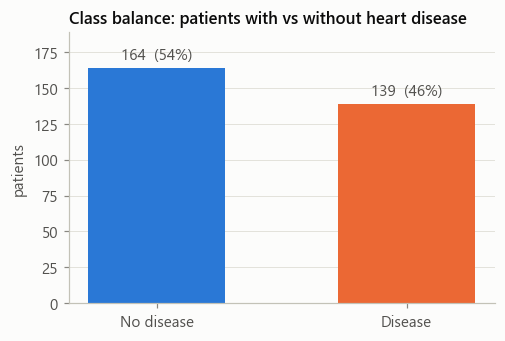

In [8]:
counts = df[config.TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(
    [plotting.CLASS_NAMES[k] for k in counts.index], counts.values, width=0.55,
    color=[plotting.CLASS_COLORS[k] for k in counts.index],
)
for bar, n in zip(bars, counts.values):
    ax.annotate(f"{n}  ({n / counts.sum():.0%})", (bar.get_x() + bar.get_width() / 2, n),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
                color=plotting.INK_SECONDARY)
ax.set_title("Class balance: patients with vs without heart disease")
ax.set_ylabel("patients")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, counts.max() * 1.15)
plotting.save(fig, FIG / "eda_class_balance.png")
plt.show()

## 4 · Numeric feature distributions by class

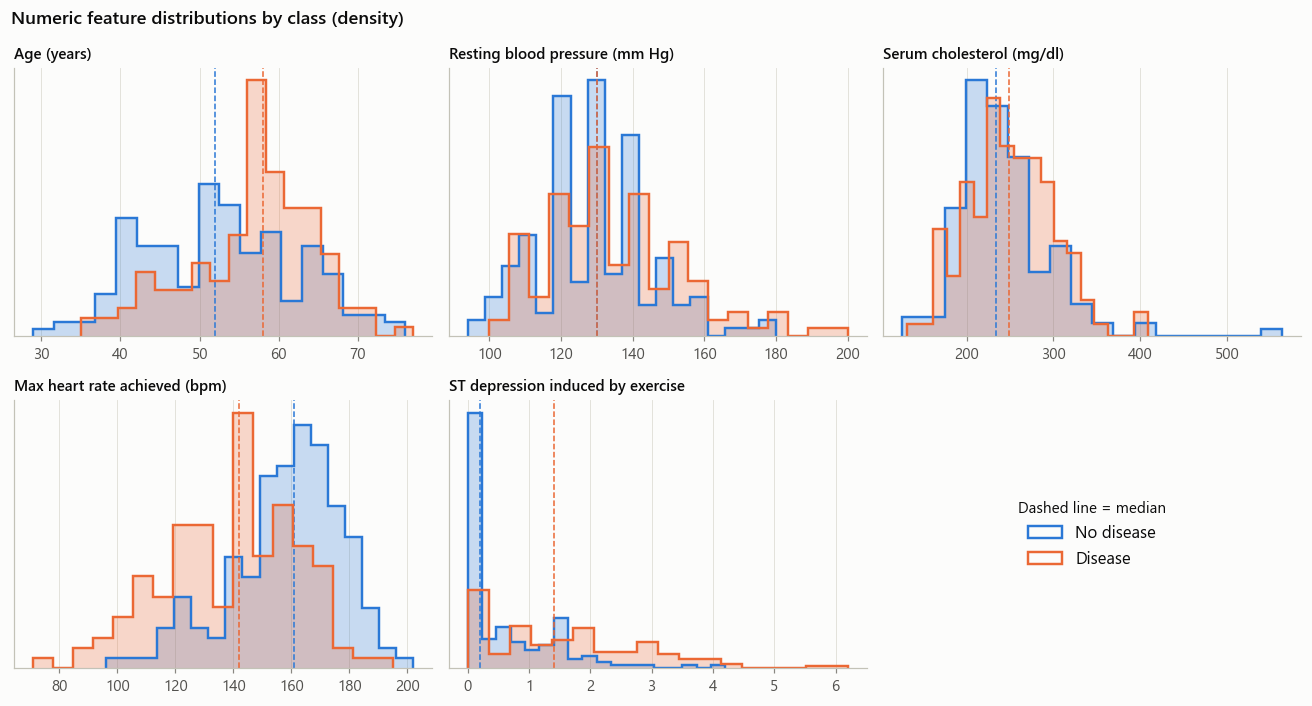

In [9]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
titles = {
    "age": "Age (years)", "trestbps": "Resting blood pressure (mm Hg)",
    "chol": "Serum cholesterol (mg/dl)", "thalach": "Max heart rate achieved (bpm)",
    "oldpeak": "ST depression induced by exercise",
}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, col in zip(axes.flat, num_cols):
    for cls in (0, 1):
        vals = df.loc[df[config.TARGET] == cls, col]
        ax.hist(vals, bins=18, histtype="stepfilled", alpha=0.25,
                color=plotting.CLASS_COLORS[cls], density=True)
        ax.hist(vals, bins=18, histtype="step", linewidth=1.6,
                color=plotting.CLASS_COLORS[cls], density=True,
                label=plotting.CLASS_NAMES[cls])
        ax.axvline(vals.median(), color=plotting.CLASS_COLORS[cls], linestyle="--", linewidth=1)
    ax.set_title(titles[col], fontsize=10)
    ax.set_yticks([])
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", fontsize=11, title="Dashed line = median")
fig.suptitle("Numeric feature distributions by class (density)", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
plotting.save(fig, FIG / "eda_numeric_histograms.png")
plt.show()

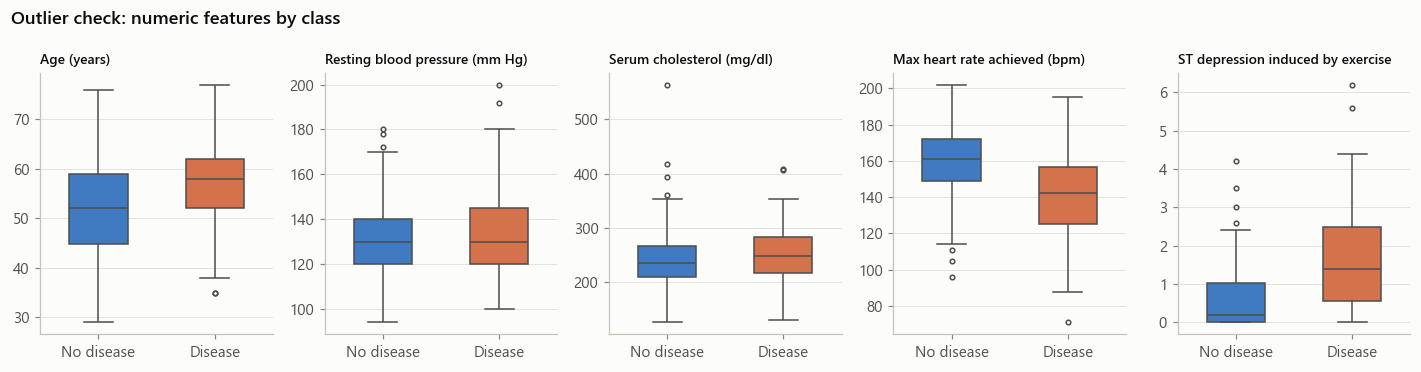

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.4))
palette = {plotting.CLASS_NAMES[k]: v for k, v in plotting.CLASS_COLORS.items()}
plot_df = df.assign(cls=df[config.TARGET].map(plotting.CLASS_NAMES))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=plot_df, x="cls", y=col, hue="cls", palette=palette, ax=ax, width=0.5,
                linewidth=1, fliersize=3, legend=False)
    ax.set_title(titles[col], fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
fig.suptitle("Outlier check: numeric features by class", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
plotting.save(fig, FIG / "eda_numeric_boxplots.png")
plt.show()

## 5 · Categorical features: disease rate per category

Raw counts per category say little. The useful question is **what share of patients in each category
have heart disease**. The dashed line marks the overall rate. Bars far from it point to strong signal.

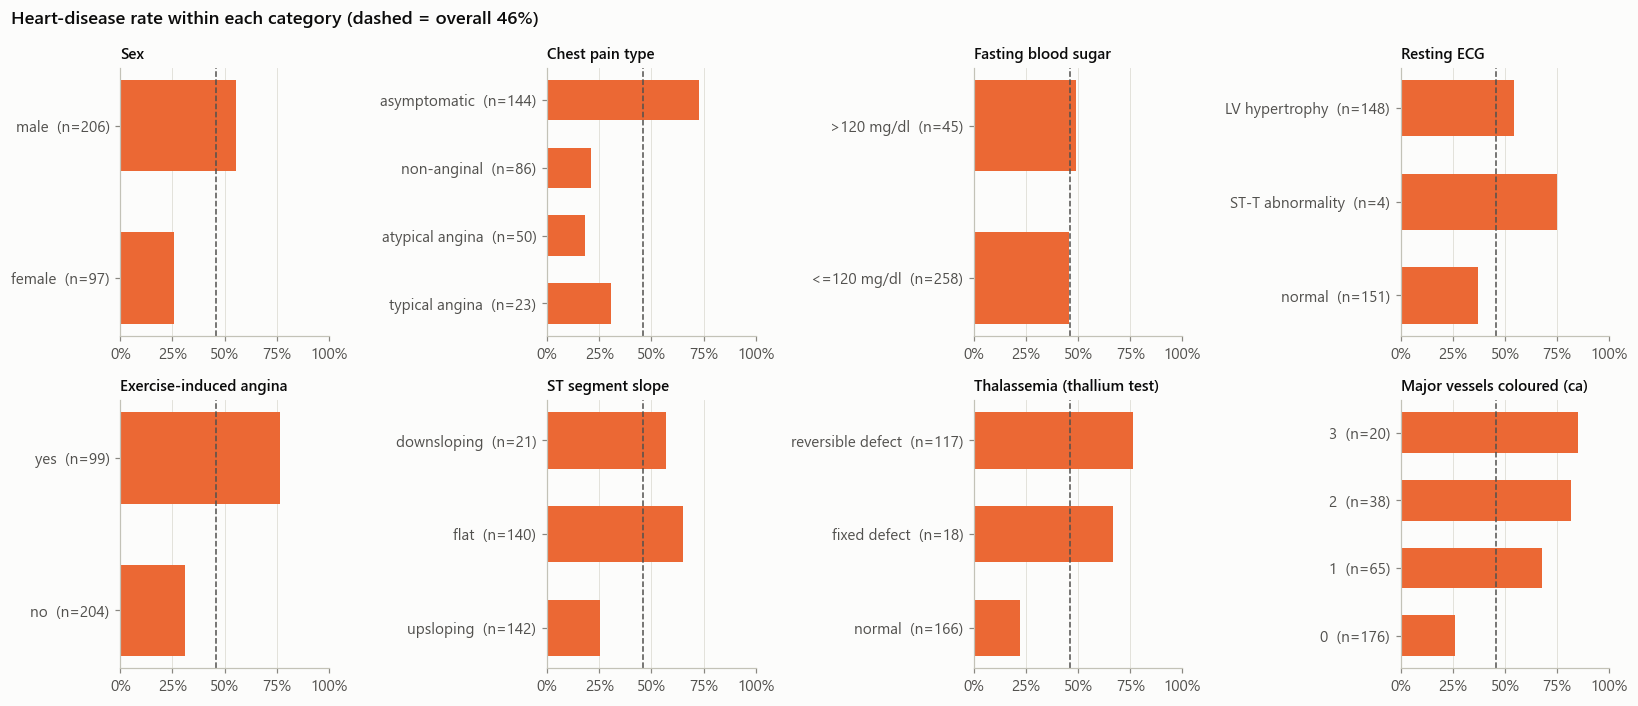

In [11]:
cat_cols = config.CATEGORICAL_FEATURES + ["ca"]
cat_titles = {
    "sex": "Sex", "cp": "Chest pain type", "fbs": "Fasting blood sugar",
    "restecg": "Resting ECG", "exang": "Exercise-induced angina", "slope": "ST segment slope",
    "thal": "Thalassemia (thallium test)", "ca": "Major vessels coloured (ca)",
}
base_rate = df[config.TARGET].mean()
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.flat, cat_cols):
    g = df.groupby(col, dropna=True)[config.TARGET].agg(["mean", "size"])
    labels = [
        f"{config.CATEGORY_LABELS.get(col, {}).get(int(i), str(int(i)))}  (n={n})"
        for i, n in zip(g.index, g["size"])
    ]
    ax.barh(labels, g["mean"], color=plotting.CLASS_COLORS[1], height=0.6)
    ax.axvline(base_rate, color=plotting.INK_SECONDARY, linestyle="--", linewidth=1)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(cat_titles[col], fontsize=10)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Heart-disease rate within each category (dashed = overall {base_rate:.0%})",
             x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
plotting.save(fig, FIG / "eda_categorical_disease_rate.png")
plt.show()

## 6 · Correlation analysis

Spearman rank correlation is used instead of Pearson. Most features are ordinal codes or skewed, and Spearman
only assumes a monotonic relationship. The upper triangle is masked because it repeats the lower one.

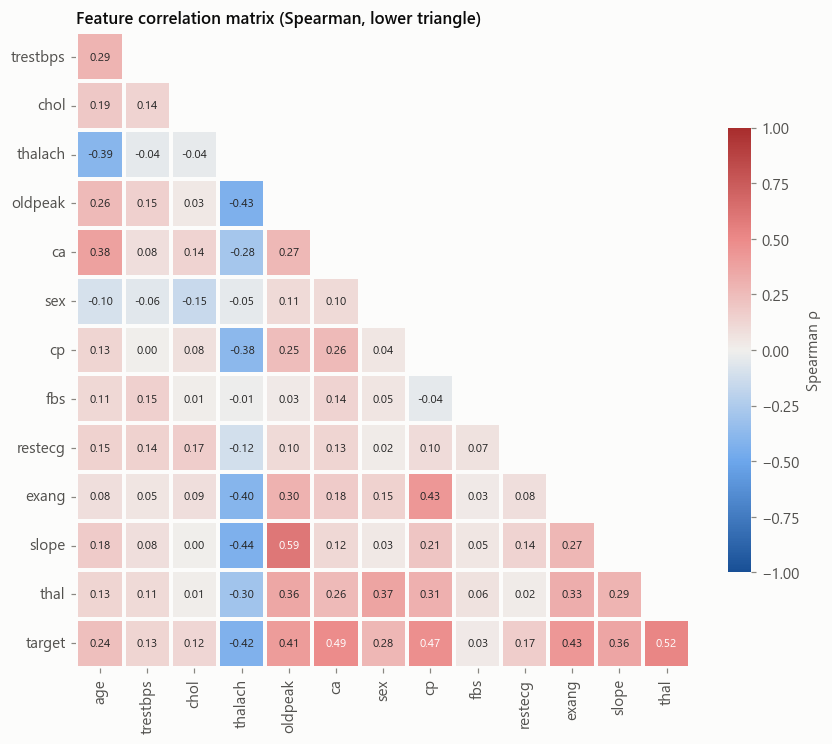

In [12]:
corr = df.astype(float).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr.iloc[1:, :-1], mask=mask[1:, :-1], cmap=plotting.DIVERGING, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=1.5,
            linecolor=plotting.SURFACE, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Feature correlation matrix (Spearman, lower triangle)")
ax.grid(False)
plotting.save(fig, FIG / "eda_correlation_heatmap.png")
plt.show()

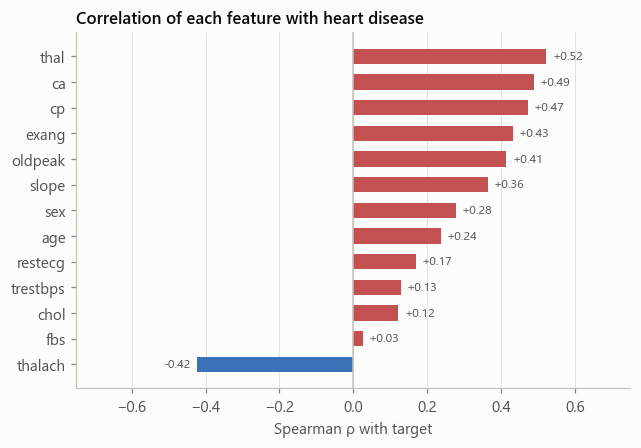

,rho_with_target
thal,0.52
ca,0.49
cp,0.47
exang,0.43
thalach,-0.42
oldpeak,0.41
slope,0.36
sex,0.28
age,0.24
restecg,0.17


In [13]:
target_corr = corr[config.TARGET].drop(config.TARGET).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4.2))
colors = [plotting.DIVERGING(0.1) if v < 0 else plotting.DIVERGING(0.9) for v in target_corr]
ax.barh(target_corr.index, target_corr.values, color=colors, height=0.6)
for y, v in enumerate(target_corr.values):
    ax.annotate(f"{v:+.2f}", (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", fontsize=8,
                color=plotting.INK_SECONDARY)
ax.axvline(0, color=plotting.BASELINE, linewidth=1)
ax.set_xlim(-0.75, 0.75)
ax.set_title("Correlation of each feature with heart disease")
ax.set_xlabel("Spearman ρ with target")
ax.grid(axis="y", visible=False)
plotting.save(fig, FIG / "eda_target_correlation.png")
plt.show()
target_corr.sort_values(key=abs, ascending=False).to_frame("rho_with_target")

In [14]:
# Pairs of features that are strongly correlated with each other (possible redundancy)
feat_corr = corr.drop(index=config.TARGET, columns=config.TARGET)
lower = feat_corr.where(np.tril(np.ones(feat_corr.shape, dtype=bool), k=-1))
strong = lower.stack().loc[lambda s: s.abs() >= 0.4].sort_values(key=abs, ascending=False)
strong.to_frame("rho")

rho
slope   oldpeak  0.59
        thalach -0.44
exang   cp       0.43
oldpeak thalach -0.43
exang   thalach -0.40

## 7 · Save cleaned dataset

In [15]:
save_clean(df)  # LF line endings on every OS
print(f"saved {config.CLEAN_FILE.relative_to(config.PROJECT_ROOT)}  shape={df.shape}")

saved data\processed\heart_clean.csv  shape=(303, 14)


## 8 · Key findings

**Data quality**
- 303 patients, 13 features, no duplicate rows. Only **6 cells are missing** (`ca` 1.3%, `thal` 0.7%), spread across both
  classes, so imputation inside the pipeline is safe and no rows need dropping.
- Extreme values (cholesterol 564 mg/dl, ST depression 6.2, BP 200 mm Hg) are clinically plausible readings, not
  entry errors. They are **kept**. Scaling handles them for linear models, and tree models are insensitive to them.

**Target**
- Classes are close to balanced (**54% / 46%**). No resampling is needed. Splits and CV folds will be **stratified**, and
  **ROC-AUC** is the primary selection metric because it does not depend on a threshold. **Recall** comes second: a missed
  disease case (false negative) costs more than a false alarm.

**Strongest signals**
- `thal`: reversible defect gives 76% disease vs 22% for normal.
- `ca`: a clean monotonic step from 26% (0 vessels) to 85% (3 vessels).
- `cp`: *asymptomatic* chest pain gives 73% disease vs about 20% for the other types. This looks counter-intuitive, but it is a known
  pattern in this cohort, because patients with silent ischaemia were referred for angiography.
- `exang` (77% vs 31%), `oldpeak` and `thalach` (ρ = −0.42: lower max heart rate means more disease).

**Weak signals**
- `fbs` (ρ = 0.03), `chol` (0.12) and `trestbps` (0.13) separate the classes poorly on their own. They are kept for now and
  checked through model feature importances and an ablation.

**Encoding implications**
- `cp`, `thal`, `restecg` and `slope` are **nominal codes**, not quantities. They are one-hot encoded, not scaled.
- `restecg = 1` (ST-T abnormality) has only **4 patients**. The encoder must tolerate categories that are rare or unseen in a
  fold (`handle_unknown="ignore"`).
- No feature pair exceeds |ρ| = 0.6 (the largest is `slope`–`oldpeak` at 0.59), so multicollinearity is mild. All features
  stay, and logistic regression's L2/L1 regularisation absorbs what remains.
- `age` and `thalach` are negatively correlated (ρ = −0.39) because maximum heart rate falls with age. That motivates an
  **age-adjusted heart-rate feature**, `thalach / (220 − age)` (share of the predicted max HR reached). It will be
  tested as an engineered feature in Phase C.